# Error Analysis Task 2

Run `e2_mix`, mode balanced. Fokus pada CONDA bench (domain game) dan NoisyHate (penyamaran).

## Setup

In [1]:
# Imports and Paths
import csv
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo = Path.cwd()
while not (repo / "pyproject.toml").exists():
    repo = repo.parent
sys.path.insert(0, str(repo / "src" / "task_2"))

from config import CATS, OUT, RUNS, TOXIC_INTENTS

RAW = repo / "data" / "raw"
JIGSAW = RAW / "jigsaw"
HAS_JIGSAW = (JIGSAW / "train.csv").exists()
RUN = "e2_mix"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
print("Jigsaw lokal:", HAS_JIGSAW)

Jigsaw lokal: False


In [2]:
# Plot Style
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#b4b2ab", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#6b6a65", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
    "legend.frameon": False,
})

In [3]:
# Task 2 Sets
# CONDA dan NoisyHate dari prepare.py (tidak butuh Jigsaw), Jigsaw hanya jika ada
import prepare
from common import load_set

if not (OUT / "conda_bench.tsv").exists():
    prepare.prepare_conda()
    prepare.prepare_noisyhate()
if HAS_JIGSAW and not (OUT / "jigsaw_test.tsv").exists():
    prepare.prepare_jigsaw()

In [4]:
# Classifier
from predict import ToxicityClassifier

clf = ToxicityClassifier(RUN, mode="balanced")
th = clf.th
print("ambang gate:", th["gate"])

/home/nazihstei/git/personal/IF5153-Chat-Moderation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ambang gate: {'balanced': 0.44167301058769226, 'strict': 0.8749346137046814}


## 1. Setting dan Hasil

In [5]:
# Settings
cfg = json.loads((RUNS / RUN / "config.json").read_text())
keep = ["sources", "conda_text", "jigsaw_neg_frac", "epochs", "lr", "bs", "max_len", "seed", "n_train", "seconds"]
display(pd.Series({k: str(cfg[k]) for k in keep}))
pd.DataFrame(cfg["log"]).set_index("epoch")

sources                 jigsaw,conda
conda_text                  norm,raw
jigsaw_neg_frac                 0.35
epochs                             3
lr                             3e-05
bs                                32
max_len                          128
seed                            2026
n_train                       121221
seconds            5679.444604635239
dtype: str

,train_loss,score,conda_gate_ap,jigsaw_cat_ap
epoch,,,,
1,0.163,0.812,0.931,0.692
2,0.104,0.831,0.945,0.717
3,0.081,0.830,0.942,0.719


In [6]:
# Arm Comparison
# dari output summary.py di notebook Colab Task 2 (bobot arm lain tidak tersedia lokal)
arms = pd.DataFrame({
    "b0_tfidf": [0.893, 0.842, 0.026, 0.033, 0.886, 0.680, 0.835, 0.842, 0.600, 0.400, 0.512],
    "e1_jigsaw": [0.660, 0.616, 0.021, 0.057, 0.748, 0.102, 0.604, 0.612, 0.668, 0.602, 0.692],
    "e2_mix": [0.902, 0.849, 0.010, 0.036, 0.884, 0.733, 0.850, 0.851, 0.665, 0.533, 0.629],
    "z_toxicbert": [0.675, 0.638, 0.021, 0.058, 0.799, 0.089, 0.629, 0.638, 0.662, 0.620, 0.721],
}, index=["bench norm gate AP", "bench norm F1", "bench FPR A", "bench FPR O", "bench recall E", "bench recall I",
          "bench raw F1", "bench t1pred F1", "jigsaw test macro AP", "noisyhate recall perturbed",
          "noisyhate recall t1pred"])
arms

,b0_tfidf,e1_jigsaw,e2_mix,z_toxicbert
bench norm gate AP,0.893,0.660,0.902,0.675
bench norm F1,0.842,0.616,0.849,0.638
bench FPR A,0.026,0.021,0.010,0.021
bench FPR O,0.033,0.057,0.036,0.058
bench recall E,0.886,0.748,0.884,0.799
bench recall I,0.680,0.102,0.733,0.089
bench raw F1,0.835,0.604,0.850,0.629
bench t1pred F1,0.842,0.612,0.851,0.638
jigsaw test macro AP,0.600,0.668,0.665,0.662
noisyhate recall perturbed,0.400,0.602,0.533,0.620


## 2. Prediksi CONDA Bench

In [7]:
# Bench Predictions
bench = load_set("conda_bench")
for col in ["raw", "norm", "t1pred"]:
    bench[f"p_{col}"] = clf.net.probs(bench[col].tolist())[:, 0]
thr = th["gate"]["balanced"]
bench["pred"] = (bench["p_norm"] >= thr).astype(int)
bench["hasil"] = np.select([(bench.gate == 1) & (bench.pred == 1), (bench.gate == 0) & (bench.pred == 1),
                            (bench.gate == 1) & (bench.pred == 0)], ["TP", "FP", "FN"], "TN")
pd.crosstab(bench["intent"], bench["hasil"], margins=True)

hasil,FN,FP,TN,TP,All
intent,,,,,
A,0,2,190,0,192
E,55,0,0,418,473
I,60,0,0,165,225
O,0,90,2442,0,2532
All,115,92,2632,583,3422


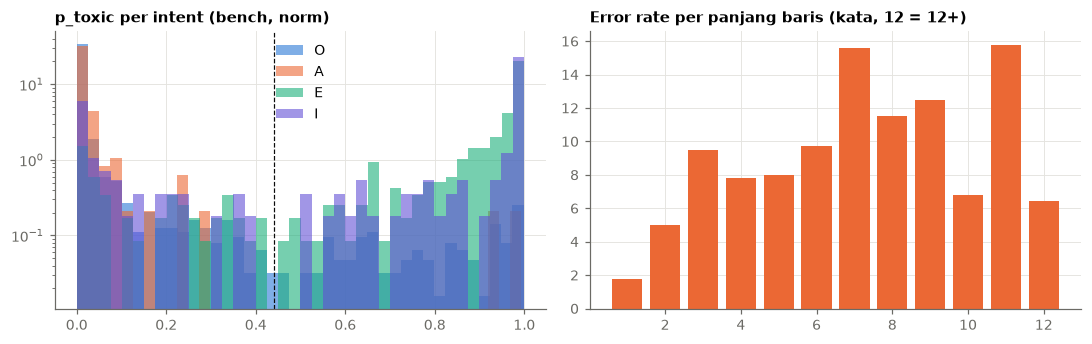

In [8]:
# Score Distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for k, color in zip(["O", "A", "E", "I"], SERIES):
    axes[0].hist(bench.loc[bench.intent == k, "p_norm"], bins=40, alpha=0.6, label=k, color=color, density=True)
axes[0].axvline(thr, color=INK, lw=0.8, ls="--")
axes[0].set_title("p_toxic per intent (bench, norm)")
axes[0].set_yscale("log")
axes[0].legend()
bench["kata"] = bench["norm"].str.split().str.len().clip(upper=12)
err = bench.groupby("kata").apply(lambda g: (g.gate != g.pred).mean())
axes[1].bar(err.index, err.values * 100, color=SERIES[1])
axes[1].set_title("Error rate per panjang baris (kata, 12 = 12+)")
fig.tight_layout()

## 3. Contoh Error

In [9]:
# False Negatives
cols = ["intent", "raw", "norm", "p_norm"]
fn = bench[bench.hasil == "FN"].sort_values("p_norm")
print("FN per intent:", fn["intent"].value_counts().to_dict())
fn.groupby("intent").head(8)[cols]

FN per intent: {'I': 60, 'E': 55}


,intent,raw,norm,p_norm
2086,I,lol,lol,8.830e-04
2090,I,lol,lol,8.830e-04
2106,I,lol,lol,8.830e-04
2087,I,?,?,9.698e-04
2130,E,mine for sure,mine for sure,1.207e-03
406,E,commend ty notlikethis,commend thank you notlikethis,1.207e-03
2662,E,commend me bara,commend me bara,1.410e-03
2111,I,sry dude,sorry dude,1.598e-03
1009,E,push ff,push ff,1.755e-03
2390,I,pudge what u said?,pudge what you said ?,1.988e-03


In [10]:
# False Positives
fp = bench[bench.hasil == "FP"].sort_values("p_norm", ascending=False)
print("FP per intent:", fp["intent"].value_counts().to_dict())
fp.groupby("intent").head(8)[cols]

FP per intent: {'O': 90, 'A': 2}


,intent,raw,norm,p_norm
2882,O,eaz,ez,0.998
1942,O,ez^,ez ^,0.997
3410,O,noobs,noobs,0.996
2767,O,=)) ez mid next time pick veng not alch,=)) ez mid next time pick veng not alchemist,0.994
1795,A,ez report,ez report,0.993
2168,O,1-9 dis talking lol,1-9 this talking lol,0.993
194,O,you're fkn joking you jumped my ult i mean my hex,you're fucking joking you jumped my ult i mean my hex,0.992
1545,O,spectre noob,spectre noob,0.991
144,O,i am still so fkn dirty about that fb. i spiked out so hard,i am still so fucking dirty about that fb . i spiked out so hard,0.988
1465,A,pls report this shity rockhead tony,please report this shitty rockhead tony,0.930


In [11]:
# Error Words
def top_words(df, n=15):
    return Counter(w for t in df["norm"] for w in set(t.split())).most_common(n)


pd.DataFrame({"FN": top_words(fn), "FP": top_words(fp)})

,FN,FP
0,"(?, 18)","(fuck, 15)"
1,"(you, 12)","(you, 13)"
2,"(to, 9)","(this, 7)"
3,"(a, 8)","(is, 7)"
4,"(report, 8)","(my, 6)"
5,"(is, 8)","(bad, 6)"
6,"(this, 8)","(?, 6)"
7,"(i, 7)","(i, 5)"
8,"(lol, 6)","(fucking, 5)"
9,"(feed, 6)","(so, 5)"


## 4. Efek Normalisasi Task 1

In [12]:
# Normalization Effect
rows = []
for col in ["raw", "norm", "t1pred"]:
    pred = bench[f"p_{col}"] >= thr
    tp, fp_, fn_ = (pred & (bench.gate == 1)).sum(), (pred & (bench.gate == 0)).sum(), (~pred & (bench.gate == 1)).sum()
    rows.append({"teks": col, "precision": tp / (tp + fp_), "recall": tp / (tp + fn_), "f1": 2 * tp / (2 * tp + fp_ + fn_)})
display(pd.DataFrame(rows).set_index("teks"))
flip = bench[(bench["p_raw"] >= thr) != (bench["p_t1pred"] >= thr)]
print("baris yang keputusannya berubah raw -> t1pred:", len(flip))
flip[["intent", "raw", "t1pred", "p_raw", "p_t1pred"]].head(12)

,precision,recall,f1
teks,,,
raw,0.872,0.830,0.850
norm,0.864,0.835,0.849
t1pred,0.866,0.837,0.851


baris yang keputusannya berubah raw -> t1pred: 28


,intent,raw,t1pred,p_raw,p_t1pred
222,O,im not after the ks bish not selfish,i'm not after the ks bitch not selfish,0.051,0.968
235,O,poor af,poor as fuck,0.151,0.926
249,O,fvck,fuck,0.192,0.660
327,O,and u fed,and you fed,0.418,0.461
424,O,becoz they are not weak u are weak,because they are not weak you are weak,0.576,0.111
687,I,alche acount buyer it seems,alche account buyer it seems,0.028,0.970
1087,O,dafuq was this luna?,the fuck was this luna ?,0.005,0.688
1208,O,wow u were so bad toplane,wow you were so bad toplane,0.274,0.535
1224,O,worth it?,worth it ?,0.466,0.367
1225,E,nob necro,noob necro,0.015,0.992


## 5. NoisyHate

In [13]:
# NoisyHate Recall
nh = load_set("noisyhate")
for col in ["perturbed", "t1pred", "clean"]:
    nh[f"p_{col}"] = clf.net.probs(nh[col].tolist())[:, 0]
display(pd.Series({c: (nh[f"p_{c}"] >= thr).mean() for c in ["perturbed", "t1pred", "clean"]}, name="recall"))
miss = nh[(nh.p_perturbed < thr) & (nh.p_clean >= thr)]
print("lolos karena penyamaran (clean terdeteksi, perturbed tidak):", len(miss),
      "| diselamatkan T1:", int((miss.p_t1pred >= thr).sum()))
miss[["perturbed", "t1pred", "clean", "p_perturbed", "p_t1pred"]].head(10)

perturbed    0.534
t1pred       0.629
clean        0.732
Name: recall, dtype: float64

lolos karena penyamaran (clean terdeteksi, perturbed tidak): 281 | diselamatkan T1: 154


,perturbed,t1pred,clean,p_perturbed,p_t1pred
1,this kind of crapp will end when trump is president,this kind of crapp will end when trump is president,this kind of crap will end when trump is president,0.281,0.281
5,you are a terribl3 person with way too much free time,you are a terrible person with way too much free time,you are a terrible person with way too much free time,0.119,0.799
8,mil up your as,mill up your as,mil up your ass,0.035,0.027
10,another loserrr like young,another loser like young,another loser like young,0.073,0.879
14,you are obviously a fol,you are obviously a fol,you are obviously a fool,0.039,0.039
16,prove that jackas,prove that jackas,prove that jackass,0.004,0.004
21,i think ill go home and kil my family said no pot smoker ever,i think i'll go home and kill my family said no pot smoker ever,i think ill go home and kill my family said no pot smoker ever,0.166,0.898
30,id rather eat my own arrse,id rather eat my own arrase,id rather eat my own arse,0.225,0.209
35,what u5eless people,what useless people,what useless people,0.043,0.896
41,you are the trolll here get over yourself,you are the troll here get over yourself,you are the troll here get over yourself,0.340,0.474


In [14]:
# NoisyHate Hard Cases
hard = nh[nh.p_clean < thr]
print("tidak terdeteksi walau teks bersih:", len(hard))
hard[["clean", "p_clean"]].head(10)

tidak terdeteksi walau teks bersih: 359


,clean,p_clean
0,this is pretty much exactly how i feel damn,0.047
6,if they only had a brain,0.158
7,darn federal overreach,0.005
9,why not just shoot him and put him in the freezer,0.282
17,this would not be a story if she was ugly or black especially if she was both,0.315
23,damn i miss this guy,0.188
24,all the revenue should at least cover for that damned art tax,0.232
33,bullet to the head end of story,0.016
34,surprise surprise ridiculous,0.041
36,oh right ridiculous,0.089


## 6. Kategori Jigsaw

In [15]:
# Jigsaw Category Errors
if HAS_JIGSAW:
    test = load_set("jigsaw_test")
    p = clf.net.probs(test["text"].tolist())
    rows = []
    for k, c in enumerate(CATS):
        pred = p[:, 1 + k] >= th["cats"][c]
        y = test[c].values == 1
        rows.append({"kategori": c, "positif": int(y.sum()), "precision": (pred & y).sum() / max(pred.sum(), 1),
                     "recall": (pred & y).sum() / max(y.sum(), 1)})
    display(pd.DataFrame(rows).set_index("kategori"))
else:
    print("Jigsaw tidak ada di data/raw/jigsaw, bagian ini dilewati")

Jigsaw tidak ada di data/raw/jigsaw, bagian ini dilewati
